# Clasificación supervisada de preguntas frecuentes de la UPQ
**Tarea especial 2/2 — Fundamentos de Inteligencia Artificial**

**Objetivo:** entrenar y comparar SVM lineal y Naive Bayes multinomial para identificar la intención de preguntas sobre la Universidad Politécnica de Querétaro. Se utiliza TF-IDF, aprendizaje supervisado local y una partición estratificada común. El modelo predice una intención; la recuperación de respuestas y el fallback corresponden al motor del chatbot.

**Ejecución:** colocar este notebook junto a `dataset_upq.csv` (versión de 1,889 preguntas). Instalar `pandas numpy scikit-learn joblib matplotlib jupyter` y ejecutar las celdas en orden. No requiere servicios externos.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
SEMILLA = 42
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.8.0


## 1. Carga y revisión del corpus
El CSV contiene texto, intención y respuesta. Solo el texto entra al clasificador y la intención es la etiqueta objetivo. La respuesta no se utiliza como variable predictora, para evitar fuga de información.

In [ ]:
ruta = Path('dataset_upq.csv')
df = pd.read_csv(ruta, encoding='utf-8-sig', dtype=str)
assert {'texto', 'intencion', 'respuesta'}.issubset(df.columns), 'Revisar las columnas del CSV'
df = df[['texto', 'intencion', 'respuesta']].copy()
print('Registros originales:', len(df))
print('Nulos por columna:')
print(df.isna().sum())
display(df.head())

Registros originales: 1889
Nulos por columna:
texto        0
intencion    0
respuesta    0
dtype: int64


,texto,intencion,respuesta
0,¿Donde esta ubicada la Universidad Politecnica...,ubicacion,La Universidad Politecnica de Queretaro (UPQ) ...
1,¿Cual es la direccion de la UPQ?,ubicacion,La direccion oficial de la UPQ es: Carretera E...
2,¿En que municipio esta la UPQ?,ubicacion,La UPQ esta ubicada en el municipio de El Marq...
3,¿Como llego a la Universidad Politecnica de Qu...,ubicacion,Puedes llegar a la UPQ por la Carretera Estata...
4,¿Donde queda el campus de la UPQ?,ubicacion,El campus de la Universidad Politecnica de Que...


## 2. Preprocesamiento
Se eliminan registros sin texto o etiqueta, se quitan espacios externos y se convierte el texto a minúsculas, igual que en los scripts originales. TF-IDF elimina los acentos durante la vectorización. Se comprueban duplicados y conflictos de etiquetas sin modificar silenciosamente el corpus.

Registros utilizables: 1889
Textos repetidos: 0
Textos con etiquetas contradictorias: 0


,Preguntas
intencion,
actividades,129
admision,133
becas,141
biblioteca,119
calendario_escolar,109
carreras,120
contacto,138
costo_admision,134
estadias,128


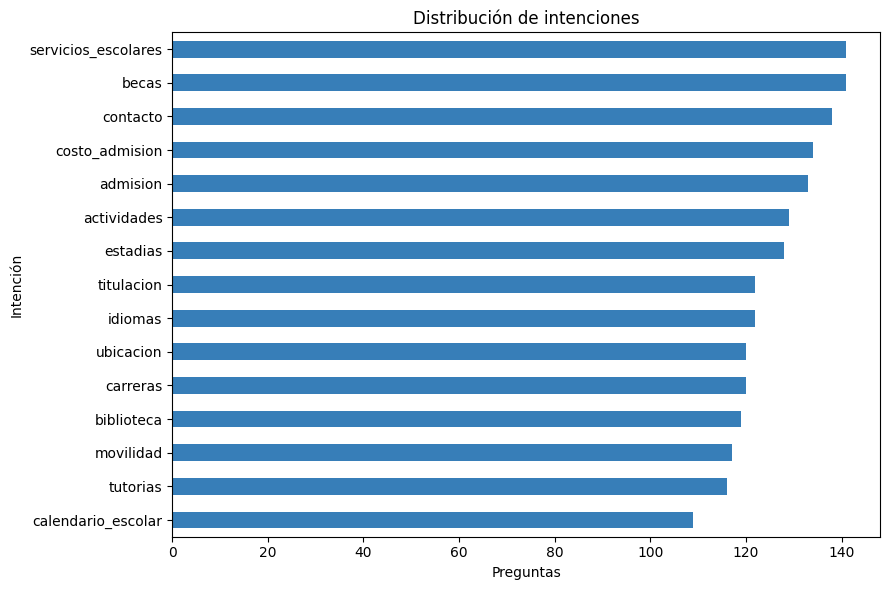

In [ ]:
df = df.dropna(subset=['texto', 'intencion']).copy()
df['texto'] = df['texto'].str.lower().str.strip()
df['intencion'] = df['intencion'].str.strip()
df = df.loc[df['texto'].ne('') & df['intencion'].ne('')].copy()
print('Registros utilizables:', len(df))
print('Textos repetidos:', df['texto'].duplicated().sum())
conflictos = df.groupby('texto')['intencion'].nunique().gt(1).sum()
print('Textos con etiquetas contradictorias:', conflictos)
conteos = df['intencion'].value_counts().sort_index()
display(conteos.to_frame('Preguntas'))
assert conteos.min() >= 20
ax = conteos.sort_values().plot.barh(figsize=(9,6), color='#377eb8')
ax.set(title='Distribución de intenciones', xlabel='Preguntas', ylabel='Intención')
plt.tight_layout(); plt.show()

## 3. División de datos
Se reserva el 20% para prueba y se utiliza el 80% para entrenamiento. La estratificación conserva la proporción de clases. La búsqueda de parámetros utiliza únicamente entrenamiento, mediante tres particiones estratificadas (igual que `cv=3` en los scripts originales).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['texto'], df['intencion'], test_size=0.2, random_state=SEMILLA,
    stratify=df['intencion'])
cv = StratifiedKFold(n_splits=3, shuffle=False)
print(f'Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}')
print('Textos idénticos presentes en ambas particiones:', len(set(X_train) & set(X_test)))

Entrenamiento: 1511 | Prueba: 378
Textos idénticos presentes en ambas particiones: 0


## 4. Vectorización TF-IDF y modelos
TF-IDF representa cada pregunta mediante pesos de términos según su frecuencia en el documento y su rareza en el corpus. SVM lineal aprende fronteras de decisión entre clases; MultinomialNB estima la clase a partir de la evidencia de los términos. Cada Pipeline ajusta su propio TF-IDF dentro de cada fold, evitando aprender vocabulario de la prueba. Se reproducen las rejillas originales de parámetros.

In [ ]:
comunes = {'tfidf__ngram_range': [(1,1), (1,2)], 'tfidf__min_df': [1,2],
           'tfidf__sublinear_tf': [True, False]}
configuraciones = {
    'SVM': (Pipeline([('tfidf', TfidfVectorizer(strip_accents='unicode')),
                      ('svm', LinearSVC(random_state=SEMILLA))]),
            {**comunes, 'svm__C': [0.1,0.5,1,2,5,10],
             'svm__class_weight': [None,'balanced']}),
    'Naive Bayes': (Pipeline([('tfidf', TfidfVectorizer(strip_accents='unicode')),
                              ('nb', MultinomialNB())]),
                    {**comunes, 'nb__alpha': [0.01,0.05,0.1,0.5,1.0],
                     'nb__fit_prior': [True,False]})}
busquedas = {}
for nombre, (pipeline, parametros) in configuraciones.items():
    busqueda = GridSearchCV(pipeline, parametros, cv=cv, scoring='f1_macro',
                            n_jobs=2, verbose=1)
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    print(nombre, '| F1 macro CV:', round(busqueda.best_score_,4))
    print(busqueda.best_params_)

Fitting 3 folds for each of 96 candidates, totalling 288 fits


SVM | F1 macro CV: 0.8392
{'svm__C': 0.5, 'svm__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': False}
Fitting 3 folds for each of 80 candidates, totalling 240 fits


Naive Bayes | F1 macro CV: 0.7696
{'nb__alpha': 0.5, 'nb__fit_prior': False, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}


### Ejemplo de representación numérica
Se inspecciona el vectorizador SVM ya entrenado; no se vuelve a ajustar con preguntas de prueba.

In [ ]:
vectorizador = busquedas['SVM'].best_estimator_.named_steps['tfidf']
ejemplo = vectorizador.transform([X_train.iloc[0]])
print('Pregunta:', X_train.iloc[0])
print('Dimensión:', ejemplo.shape)
display(pd.DataFrame({'termino': vectorizador.get_feature_names_out()[ejemplo.indices],
                      'peso': ejemplo.data}).sort_values('peso', ascending=False).head(12))

Pregunta: ¿los cursos de idiomas son presenciales o en linea?
Dimensión: (1, 1503)


,termino,peso
6,presenciales,0.533383
4,linea,0.444470
0,cursos,0.379817
3,idiomas,0.360917
7,son,0.347851
5,los,0.266056
2,en,0.186032
1,de,0.130511


## 5. Evaluación de ambos modelos
Accuracy mide la proporción de aciertos. Precisión mide cuántas predicciones de una clase son correctas; recall mide cuántos ejemplos reales de esa clase se recuperan. F1 combina precisión y recall mediante su media armónica. El promedio macro da el mismo peso a cada intención.

In [ ]:
etiquetas = sorted(df['intencion'].unique())
resultados = {}; predicciones = {}; reportes = {}
for nombre, busqueda in busquedas.items():
    pred = busqueda.predict(X_test)
    predicciones[nombre] = pred
    resultados[nombre] = {
        'Accuracy': accuracy_score(y_test,pred),
        'Precision macro': precision_score(y_test,pred,average='macro',zero_division=0),
        'Recall macro': recall_score(y_test,pred,average='macro',zero_division=0),
        'F1 macro': f1_score(y_test,pred,average='macro',zero_division=0),
        'F1 CV': busqueda.best_score_}
    print('====', nombre, '====')
    print(classification_report(y_test,pred,labels=etiquetas,zero_division=0))
    reportes[nombre] = pd.DataFrame(classification_report(y_test,pred,labels=etiquetas,
                                    zero_division=0,output_dict=True)).T
comparacion = pd.DataFrame(resultados).T
display(comparacion.round(4))

==== SVM ====
                     precision    recall  f1-score   support

        actividades       0.74      0.77      0.75        26
           admision       0.71      0.81      0.76        27
              becas       0.88      1.00      0.93        28
         biblioteca       0.90      0.75      0.82        24
 calendario_escolar       0.78      0.95      0.86        22
           carreras       0.86      1.00      0.92        24
           contacto       0.84      0.75      0.79        28
     costo_admision       0.81      0.81      0.81        27
           estadias       0.92      0.92      0.92        26
            idiomas       0.89      0.71      0.79        24
          movilidad       0.82      0.78      0.80        23
servicios_escolares       1.00      0.75      0.86        28
         titulacion       0.92      1.00      0.96        24
           tutorias       0.81      0.74      0.77        23
          ubicacion       0.92      1.00      0.96        24

        

,Accuracy,Precision macro,Recall macro,F1 macro,F1 CV
SVM,0.8492,0.8538,0.8504,0.8477,0.8392
Naive Bayes,0.7963,0.8006,0.7969,0.7947,0.7696


## 6. Matrices de confusión
Las filas representan las intenciones reales y las columnas las predichas. La diagonal contiene los aciertos; los demás valores muestran las confusiones.

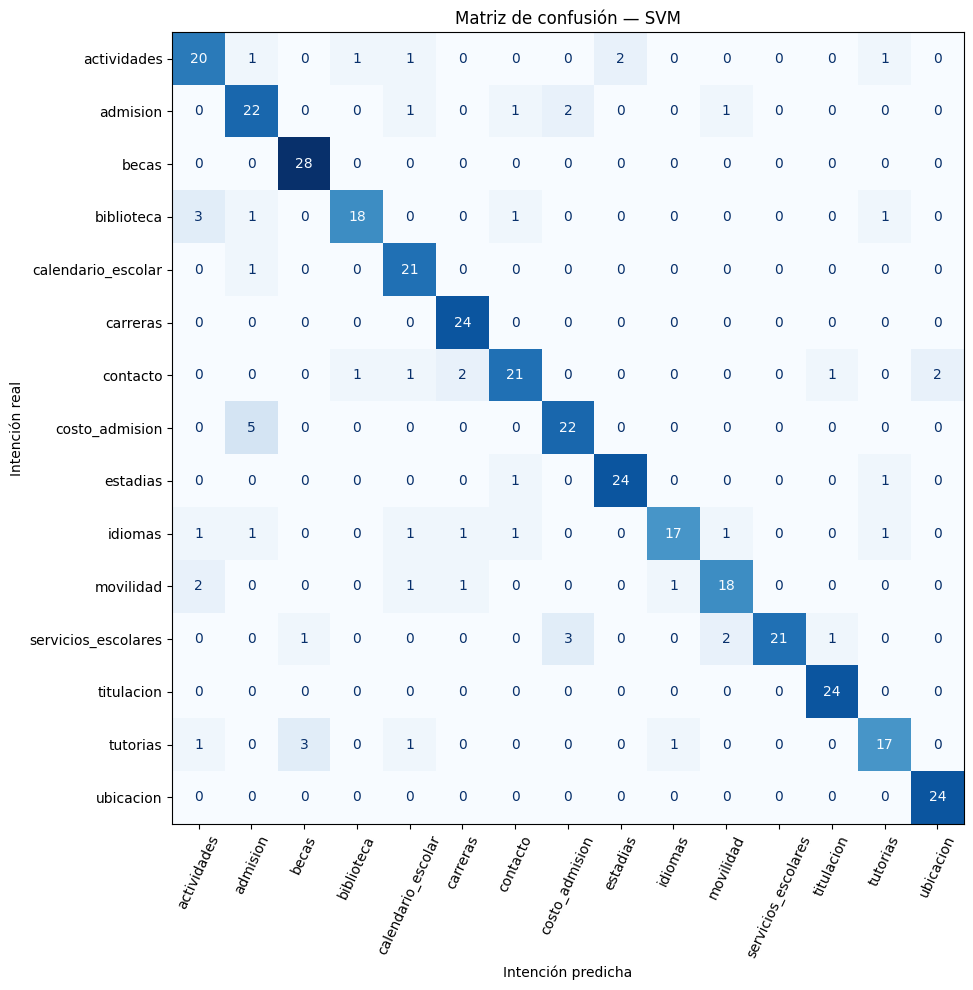

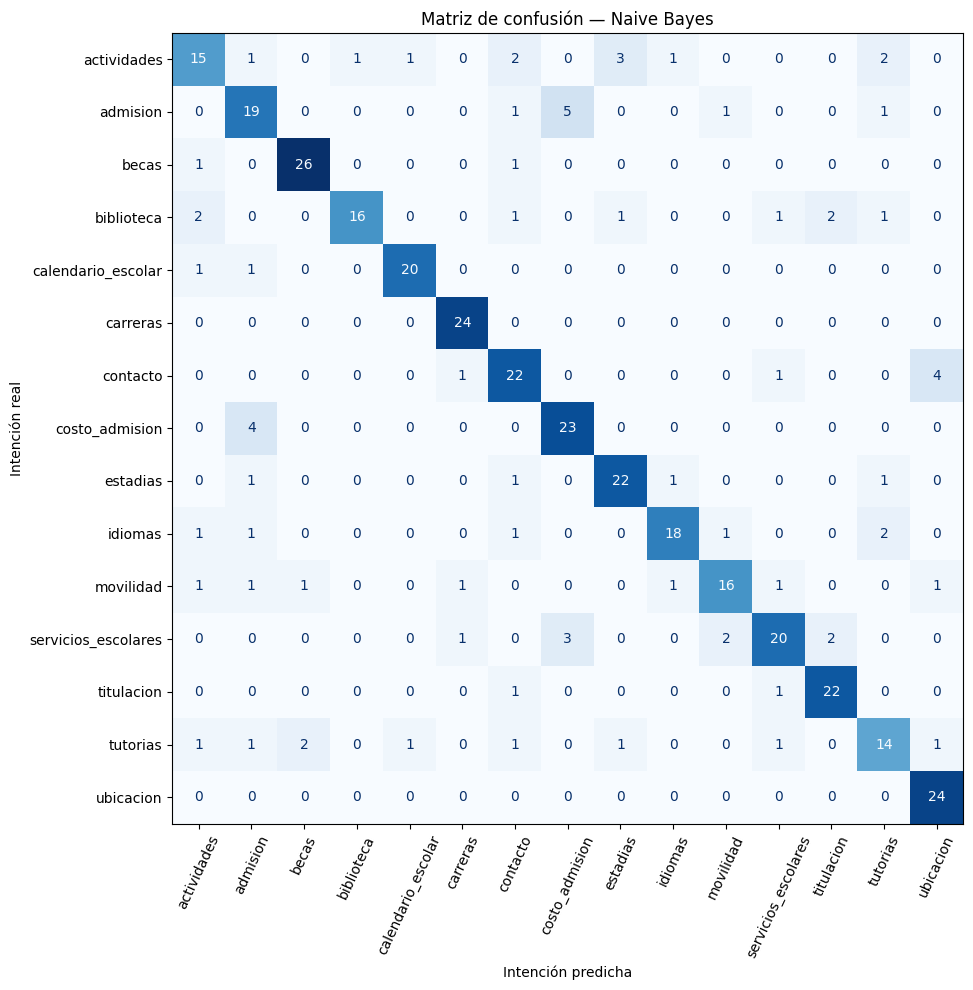

In [ ]:
for nombre, pred in predicciones.items():
    matriz = confusion_matrix(y_test,pred,labels=etiquetas)
    fig, ax = plt.subplots(figsize=(12,10))
    ConfusionMatrixDisplay(matriz,display_labels=etiquetas).plot(
        ax=ax,cmap='Blues',xticks_rotation=65,colorbar=False,values_format='d')
    ax.set(title=f'Matriz de confusión — {nombre}',xlabel='Intención predicha',ylabel='Intención real')
    plt.tight_layout(); plt.show()

## 7. Comparación visual e interpretación de errores

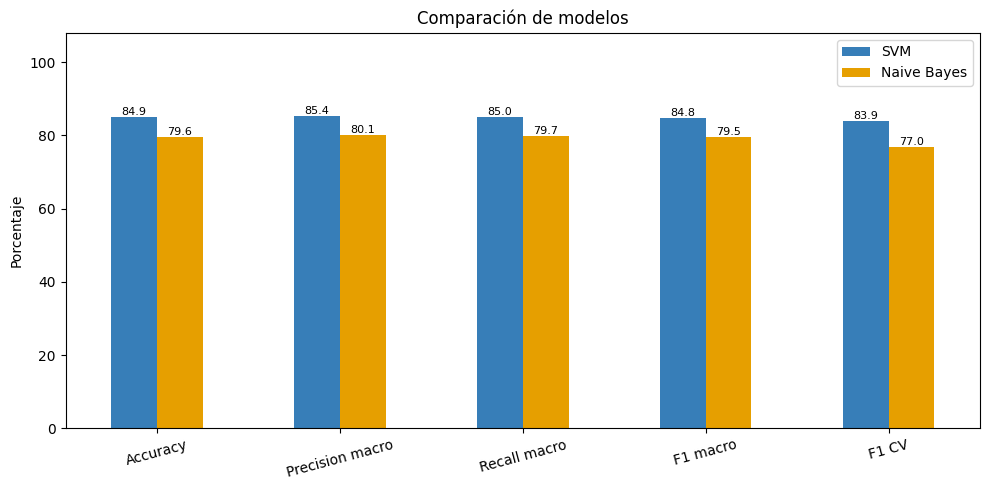

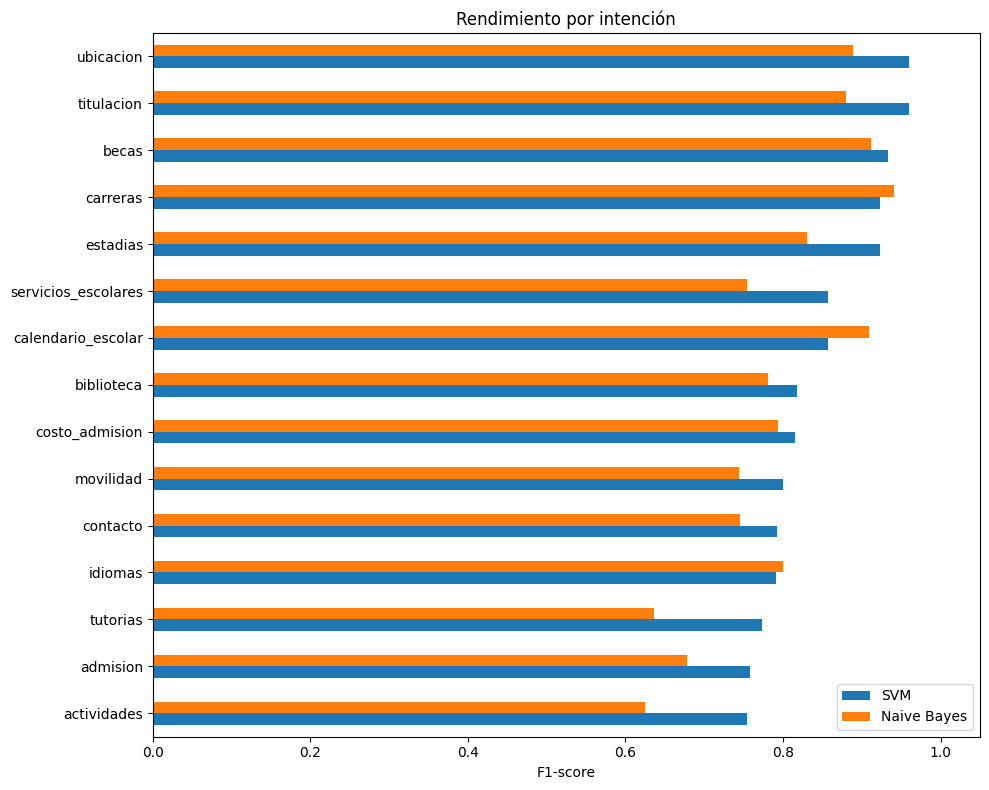

In [ ]:
ax = (comparacion.T*100).plot.bar(figsize=(10,5),color=['#377eb8','#e69f00'],rot=15)
ax.set(ylabel='Porcentaje',ylim=(0,108),title='Comparación de modelos')
for barras in ax.containers: ax.bar_label(barras,fmt='%.1f',fontsize=8)
plt.tight_layout(); plt.show()
f1_clases = pd.DataFrame({nombre: reporte.loc[etiquetas,'f1-score']
                         for nombre,reporte in reportes.items()})
ax = f1_clases.sort_values('SVM').plot.barh(figsize=(10,8))
ax.set(xlim=(0,1.05),xlabel='F1-score',title='Rendimiento por intención')
plt.tight_layout(); plt.show()

In [ ]:
mejor = comparacion['F1 CV'].idxmax()
mejor_prueba = comparacion['F1 macro'].idxmax()
print('Seleccionado por validación cruzada:', mejor)
print('Mayor F1 macro en prueba:', mejor_prueba)
print('Intenciones con menor F1 del modelo seleccionado:')
display(f1_clases[mejor].sort_values().head(5).to_frame('F1'))
matriz = confusion_matrix(y_test,predicciones[mejor],labels=etiquetas)
confusiones = [(etiquetas[i],etiquetas[j],int(matriz[i,j]))
              for i in range(len(etiquetas)) for j in range(len(etiquetas))
              if i != j and matriz[i,j]>0]
display(pd.DataFrame(confusiones,columns=['Real','Predicha','Cantidad'])
        .sort_values('Cantidad',ascending=False).head(10))
display(Markdown(f"**Conclusión de esta ejecución:** {mejor} fue seleccionado por su F1 macro "
                 f"en validación cruzada ({comparacion.loc[mejor,'F1 CV']:.2%}). "
                 f"En prueba obtuvo accuracy de {comparacion.loc[mejor,'Accuracy']:.2%} "
                 f"y F1 macro de {comparacion.loc[mejor,'F1 macro']:.2%}. "
                 f"El mayor F1 en prueba corresponde a {mejor_prueba}."))

Seleccionado por validación cruzada: SVM
Mayor F1 macro en prueba: SVM
Intenciones con menor F1 del modelo seleccionado:


,F1
actividades,0.754717
admision,0.758621
tutorias,0.772727
idiomas,0.790698
contacto,0.792453


,Real,Predicha,Cantidad
19,costo_admision,admision,5
38,tutorias,becas,3
34,servicios_escolares,costo_admision,3
9,biblioteca,actividades,3
35,servicios_escolares,movilidad,2
7,admision,costo_admision,2
18,contacto,ubicacion,2
29,movilidad,actividades,2
3,actividades,estadias,2
16,contacto,carreras,2


**Conclusión de esta ejecución:** SVM fue seleccionado por su F1 macro en validación cruzada (83.92%). En prueba obtuvo accuracy de 84.92% y F1 macro de 84.77%. El mayor F1 en prueba corresponde a SVM.

### Justificación y limitaciones
En la ejecución registrada previamente por el equipo (1,511 ejemplos de entrenamiento y 378 de prueba), SVM obtuvo accuracy de 84.92% y F1 macro de 84.77%, frente a 79.63% y 79.47% de Naive Bayes; el F1 de validación cruzada fue 83.92% y 76.96%, respectivamente. Por ello SVM es la elección inicial. Los resultados calculados arriba son los de esta ejecución y pueden variar por la versión de las librerías.

El corpus fue editado después de evaluar versiones anteriores y contiene variantes de preguntas relacionadas; por eso el resultado de prueba no garantiza el desempeño sobre consultas inéditas. Se recomienda una evaluación externa con preguntas nuevas, incluyendo consultas fuera de dominio. La exactitud de clasificación no verifica la vigencia de las respuestas oficiales ni la calidad del fallback.

## 8. Exportación de modelos
Se guardan los pipelines completos (TF-IDF y clasificador) en las rutas utilizadas por el proyecto. Para evitar sobrescribir modelos existentes accidentalmente, cambia `GUARDAR` a `True` si deseas reemplazarlos.

In [ ]:
GUARDAR = False
if GUARDAR:
    Path('modelos').mkdir(exist_ok=True)
    for nombre, archivo in [('SVM','modelo_svm.joblib'),('Naive Bayes','modelo_nb.joblib')]:
        destino = Path('modelos') / archivo
        joblib.dump(busquedas[nombre].best_estimator_, destino)
        print('Guardado:', destino)
else:
    print('Exportación desactivada; cambia GUARDAR a True para guardar los modelos.')

Exportación desactivada; cambia GUARDAR a True para guardar los modelos.
